# 8.3 PINN для теплового уравнения / 热方程 PINN
Та же задача: $u_t=u_{xx}$, $u(0,t)=0$, $u(1,t)=1$, $u(x,0)=x+\sin(\pi x)$.
与上一 Notebook 使用相同无量纲问题。解析解只用于评估，不作为内部训练数据。使用 CPU、float64 和固定随机种子。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})
blue, red = "#356AE6", "#D94F65"
import torch
from torch import nn
torch.set_num_threads(1)
torch.set_default_dtype(torch.float64)
torch.manual_seed(0)

Matplotlib is building the font cache; this may take a moment.


## Сеть и производные / 网络与导数
Tanh позволяет вычислять гладкие вторые производные. `create_graph=True` сохраняет граф для следующего дифференцирования и обучения.
使用 Tanh 获取平滑二阶导数；保留计算图，以便计算二阶导数并对损失反向传播。

In [2]:
class HeatNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 32), nn.Tanh(),
            nn.Linear(32, 32), nn.Tanh(),
            nn.Linear(32, 32), nn.Tanh(), nn.Linear(32, 1))

    def forward(self, xt):
        return self.net(xt)

def residual(model, points):
    xt = points.detach().clone().requires_grad_(True)
    u = model(xt)
    grad = torch.autograd.grad(u, xt, torch.ones_like(u), create_graph=True)[0]
    u_x, u_t = grad[:, :1], grad[:, 1:2]
    u_xx = torch.autograd.grad(u_x, xt, torch.ones_like(u_x), create_graph=True)[0][:, :1]
    return u_t - u_xx

model = HeatNet()

## Точки и функция потерь / 训练点与损失
$L=L_{PDE}+L_{BC}+L_{IC}$. 512 внутренних точек, по 64 точки на каждой границе и 64 начальные точки.
三个均方误差直接相加：方程残差、边界误差、初值误差。训练点固定，与最终评估网格分开。

In [3]:
interior = torch.rand(512, 2) * torch.tensor([1.0, 0.4])
tb = torch.linspace(0, 0.4, 64)[:, None]
left = torch.cat([torch.zeros_like(tb), tb], dim=1)
right = torch.cat([torch.ones_like(tb), tb], dim=1)
x0 = torch.linspace(0, 1, 64)[:, None]
initial = torch.cat([x0, torch.zeros_like(x0)], dim=1)
u0 = x0 + torch.sin(torch.pi * x0)

def loss_terms():
    pde = residual(model, interior).square().mean()
    bc = (model(left).square().mean() + (model(right)-1).square().mean()) / 2
    ic = (model(initial) - u0).square().mean()
    return pde, bc, ic

adam = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_history = []
for epoch in range(2000):
    adam.zero_grad()
    terms = loss_terms()
    sum(terms).backward()
    adam.step()
    loss_history.append([v.item() for v in terms])

lbfgs = torch.optim.LBFGS(model.parameters(), max_iter=500,
                         tolerance_grad=1e-10, tolerance_change=1e-12,
                         line_search_fn="strong_wolfe")
def closure():
    lbfgs.zero_grad()
    terms = loss_terms()
    loss = sum(terms)
    loss.backward()
    loss_history.append([v.item() for v in terms])
    return loss
lbfgs.step(closure)
loss_history = np.asarray(loss_history)
print("Final PDE / BC / IC losses:", [v.item() for v in loss_terms()])

Final PDE / BC / IC losses: [1.708344221644911e-06, 1.1419842178818835e-06, 5.88736440654825e-07]


## Проверка вне обучающих точек / 在训练点之外检查
Проверяем сетку 101 × 81 и отдельно новые случайные точки для невязки PDE. Шаги L-BFGS на графике — вызовы closure, не эпохи.
使用独立的 101 × 81 网格评估解误差，再用新的随机点检查方程残差。图中 L-BFGS 横轴计数为 closure 调用次数。

Grid RMSE: 5.419e-04; maximum error: 2.689e-03
PDE residual RMS at new points: 1.450e-03


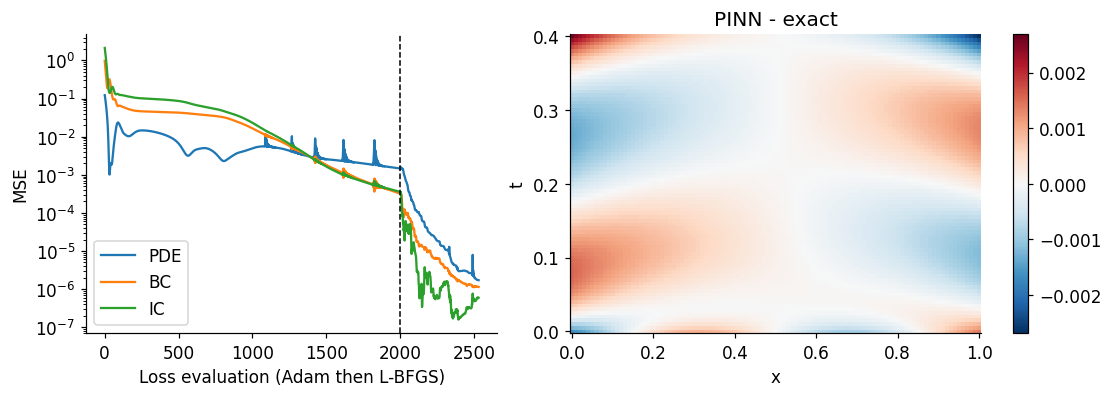

In [4]:
def exact_solution(x, t):
    return x + np.exp(-np.pi**2 * t) * np.sin(np.pi*x)

gx, gt = np.meshgrid(np.linspace(0, 1, 101), np.linspace(0, 0.4, 81))
evaluation = torch.tensor(np.column_stack([gx.ravel(), gt.ravel()]))
with torch.no_grad():
    predicted = model(evaluation).numpy().reshape(gx.shape)
reference = exact_solution(gx, gt)
error = predicted - reference
rmse = np.sqrt(np.mean(error**2))
max_error = np.max(abs(error))
fresh = torch.rand(1024, 2) * torch.tensor([1.0, 0.4])
residual_rms = residual(model, fresh).square().mean().sqrt().item()
print(f"Grid RMSE: {rmse:.3e}; maximum error: {max_error:.3e}")
print(f"PDE residual RMS at new points: {residual_rms:.3e}")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
for i, label in enumerate(["PDE", "BC", "IC"]):
    axes[0].semilogy(np.arange(1, len(loss_history)+1), loss_history[:, i], label=label)
axes[0].axvline(2000, color="black", ls="--", lw=1)
axes[0].set(xlabel="Loss evaluation (Adam then L-BFGS)", ylabel="MSE")
axes[0].legend()
image = axes[1].pcolormesh(gx, gt, error, cmap="RdBu_r", shading="auto",
                          vmin=-max_error, vmax=max_error)
axes[1].set(xlabel="x", ylabel="t", title="PINN - exact")
fig.colorbar(image, ax=axes[1])
plt.show()

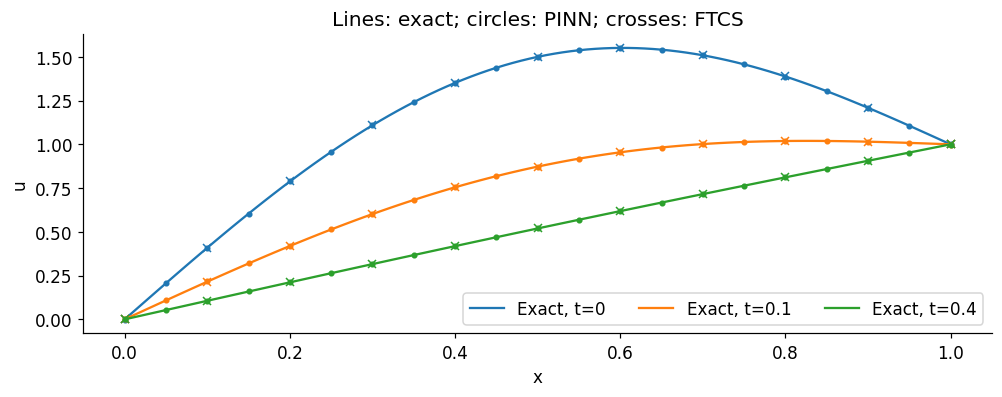

In [5]:
def exact_solution(x, t):
    return x + np.exp(-np.pi**2 * t) * np.sin(np.pi * x)

def solve_heat(nx=51, t_end=0.4, gamma=0.4):
    if nx < 3 or t_end <= 0 or not 0 < gamma <= 0.5:
        raise ValueError("Require nx >= 3, t_end > 0, 0 < gamma <= 0.5")
    x = np.linspace(0, 1, nx)
    dx = x[1] - x[0]
    nt = int(np.ceil(t_end / (gamma * dx**2)))
    times = np.linspace(0, t_end, nt + 1)
    r = (times[1] - times[0]) / dx**2
    u = exact_solution(x, 0)
    u[0], u[-1] = 0, 1
    states = [u.copy()]
    for _ in range(nt):
        new = u.copy()
        new[1:-1] = u[1:-1] + r * (u[2:] - 2*u[1:-1] + u[:-2])
        u = new
        states.append(u.copy())
    return x, times, np.asarray(states), r

x_fd, t_fd, u_fd, ratio = solve_heat()
fig, ax = plt.subplots(figsize=(9, 3.5), layout="constrained")
for t in [0, 0.1, 0.4]:
    row = np.argmin(abs(gt[:, 0] - t))
    line, = ax.plot(gx[row], reference[row], label=f"Exact, t={t}")
    ax.plot(gx[row, ::5], predicted[row, ::5], "o", ms=3, color=line.get_color())
    index = np.argmin(abs(t_fd - t))
    ax.plot(x_fd[::5], u_fd[index, ::5], "x", ms=5, color=line.get_color())
ax.set(xlabel="x", ylabel="u", title="Lines: exact; circles: PINN; crosses: FTCS")
ax.legend(ncol=3)
plt.show()

Малая невязка на обучающих точках сама по себе не доказывает точность решения. Здесь её проверяем по известному решению и независимой сетке.
训练点上的残差较小并不能单独证明解准确，这里通过解析解和独立网格检查。